In [1]:
!git clone https://github.com/alexeygrigorev/clothing-dataset-small.git

Cloning into 'clothing-dataset-small'...
remote: Enumerating objects: 3839, done.
remote: Counting objects: 100% (400/400), done.
remote: Compressing objects: 100% (400/400), done.
remote: Total 3839 (delta 9), reused 385 (delta 0), pack-reused 3439 (from 1)
Receiving objects: 100% (3839/3839), 100.58 MiB | 12.32 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

import tensorflow as tf
from tensorflow import keras

In [3]:
from tensorflow.keras.preprocessing.image import load_img

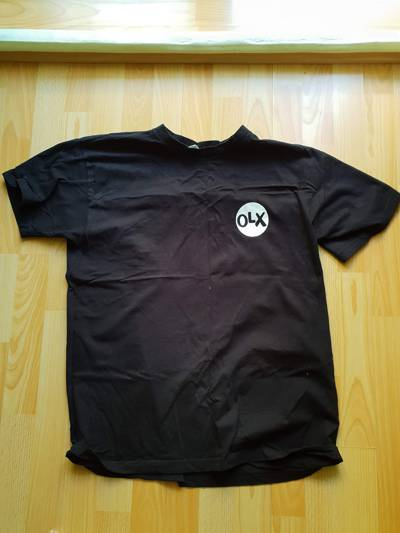

In [4]:
path = './clothing-dataset-small/train/t-shirt'
name = '5f0a3fa0-6a3d-4b68-b213-72766a643de7.jpg'
fullname = f'{path}/{name}'
load_img(fullname)

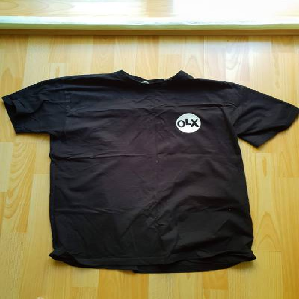

In [5]:
img = load_img(fullname, target_size=(299, 299))
img

In [6]:
x = np.array(img)
x.shape

(299, 299, 3)

array([[[179, 171,  99],
        [179, 171,  99],
        [181, 173, 101],
        ...,
        [251, 253, 248],
        [251, 253, 248],
        [251, 254, 247]],

       [[188, 179, 112],
        [187, 178, 111],
        [186, 177, 108],
        ...,
        [251, 252, 247],
        [251, 252, 247],
        [251, 252, 246]],

       [[199, 189, 127],
        [200, 190, 128],
        [200, 191, 126],
        ...,
        [250, 251, 245],
        [250, 251, 245],
        [250, 251, 245]],

       ...,

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [183, 135,  25],
        [181, 133,  22],
        [183, 135,  24]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [182, 134,  23],
        [180, 132,  21],
        [182, 134,  23]],

       [[165, 151,  76],
        [173, 159,  84],
        [171, 157,  82],
        ...,
        [181, 133,  22],
        [179, 131,  20],
        [182, 134,  23]]], dtype=uint8)
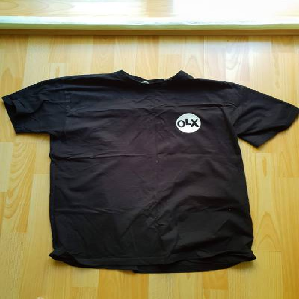

In [7]:
x

In [8]:
from tensorflow.keras.applications.xception import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.applications.xception import decode_predictions

In [9]:
model = Xception(weights='imagenet', input_shape=(299, 299, 3))

91884032/91884032 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [10]:
X = np.array([x])
X.shape

(1, 299, 299, 3)

In [11]:
X = preprocess_input(X)

In [12]:
pred = model.predict(X)
pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


(1, 1000)

In [13]:
decode_predictions(pred)

35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


[[('n03595614', 'jersey', np.float32(0.6819637)),
  ('n02916936', 'bulletproof_vest', np.float32(0.038139876)),
  ('n04370456', 'sweatshirt', np.float32(0.03432469)),
  ('n03710637', 'maillot', np.float32(0.011354209)),
  ('n04525038', 'velvet', np.float32(0.0018453572))]]

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [15]:
train_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(150, 150),
    batch_size=32
)

Found 3068 images belonging to 10 classes.


In [16]:
X, y = next(train_ds)

In [17]:
X.shape

(32, 150, 150, 3)

In [18]:
val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 341 images belonging to 10 classes.


In [19]:
def make_model(learning_rate=0.01):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)
    outputs = keras.layers.Dense(10)(vectors)
    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [20]:
scores = {}

for lr in [0.0001, 0.001, 0.01, 0.1]:
    print(lr)

    model = make_model(learning_rate=lr)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[lr] = history.history

    print()
    print()

0.0001
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 31s 224ms/step - accuracy: 0.3598 - loss: 1.9286 - val_accuracy: 0.5103 - val_loss: 1.6100
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.5681 - loss: 1.3791 - val_accuracy: 0.6246 - val_loss: 1.2490
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.6441 - loss: 1.1336 - val_accuracy: 0.6921 - val_loss: 1.0613
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.6868 - loss: 0.9958 - val_accuracy: 0.7155 - val_loss: 0.9537
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.7168 - loss: 0.9040 - val_accuracy: 0.7419 - val_loss: 0.8788
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.7344 - loss: 0.8374 - val_accuracy: 0.7507 - val_loss: 0.8273
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.7510 - loss: 0.7857 - val_accuracy: 0.7683 - val_loss: 0.7851
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms

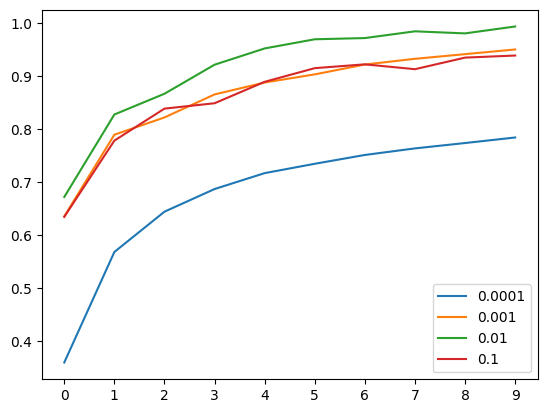

In [21]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

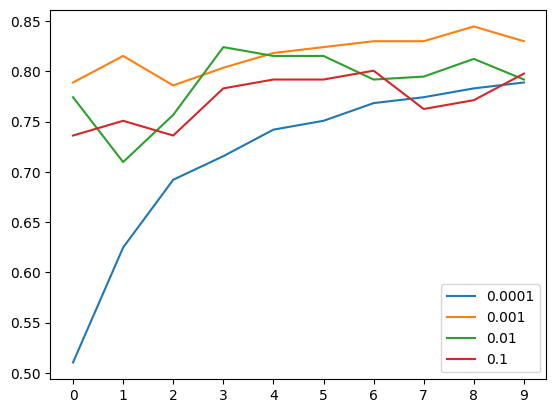

In [22]:
for lr, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=lr)

plt.xticks(np.arange(10))
plt.legend()

In [23]:
del scores[0.1]
del scores[0.0001]

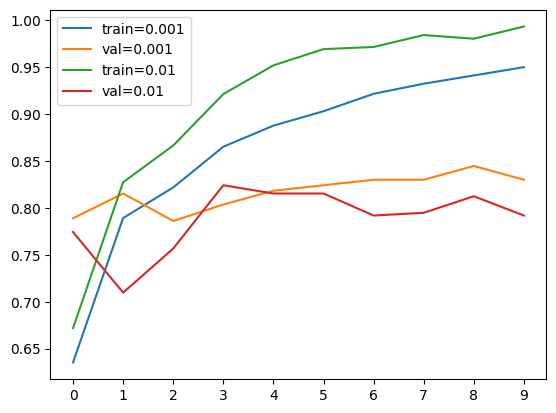

In [24]:
for lr, hist in scores.items():
    plt.plot(hist['accuracy'], label=('train=%s' % lr))
    plt.plot(hist['val_accuracy'], label=('val=%s' %lr))

plt.xticks(np.arange(10))
plt.legend()

In [25]:
learning_rate = 0.001

In [26]:
model.save_weights('model_v1.weights.h5')

In [27]:
checkpoint = keras.callbacks.ModelCheckpoint(
    'xception_v1_{epoch:02d}_{val_accuracy:.3f}.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

In [28]:
learning_rate = 0.001

model = make_model(learning_rate=learning_rate)

history = model.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds,
    callbacks=[checkpoint]
)

Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.5151 - loss: 1.4484

96/96 ━━━━━━━━━━━━━━━━━━━━ 24s 177ms/step - accuracy: 0.6353 - loss: 1.0940 - val_accuracy: 0.7742 - val_loss: 0.7383
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.7823 - loss: 0.6408

96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - accuracy: 0.7849 - loss: 0.6251 - val_accuracy: 0.8006 - val_loss: 0.6356
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8420 - loss: 0.5000

96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.8318 - loss: 0.5082 - val_accuracy: 0.8065 - val_loss: 0.5964
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - accuracy: 0.8647 - loss: 0.4310 - val_accuracy: 0.8006 - val_loss: 0.5777
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.8914 - loss: 0.3712

96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.8905 - loss: 0.3685 - val_accuracy: 0.8152 - val_loss: 0.5534
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.9073 - loss: 0.3267

96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.9107 - loss: 0.3234 - val_accuracy: 0.8240 - val_loss: 0.5520
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9276 - loss: 0.2825

96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.9175 - loss: 0.2889 - val_accuracy: 0.8328 - val_loss: 0.5394
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.9312 - loss: 0.2582 - val_accuracy: 0.8123 - val_loss: 0.5273
Epoch 9/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.9430 - loss: 0.2315 - val_accuracy: 0.8211 - val_loss: 0.5416
Epoch 10/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.9518 - loss: 0.2106 - val_accuracy: 0.8123 - val_loss: 0.5471


In [29]:
def make_model(learning_rate=0.01, size_inner=100):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)

    outputs = keras.layers.Dense(10)(inner)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [30]:
learning_rate = 0.001

scores = {}

for size in [10, 100, 1000]:
    print(size)

    model = make_model(learning_rate=learning_rate, size_inner=size)
    history = model.fit(train_ds, epochs=10, validation_data=val_ds)
    scores[size] = history.history

    print()
    print()

10
Epoch 1/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 24s 180ms/step - accuracy: 0.4866 - loss: 1.5621 - val_accuracy: 0.5953 - val_loss: 1.1253
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.6897 - loss: 0.9177 - val_accuracy: 0.7566 - val_loss: 0.7491
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.7898 - loss: 0.6368 - val_accuracy: 0.8006 - val_loss: 0.6220
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - accuracy: 0.8269 - loss: 0.5138 - val_accuracy: 0.7918 - val_loss: 0.6408
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.8585 - loss: 0.4308 - val_accuracy: 0.8240 - val_loss: 0.5704
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 90ms/step - accuracy: 0.8895 - loss: 0.3600 - val_accuracy: 0.8035 - val_loss: 0.5991
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - accuracy: 0.9078 - loss: 0.3134 - val_accuracy: 0.7977 - val_loss: 0.5997
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - accuracy: 0.9234 - loss: 0.2678 - val_accuracy

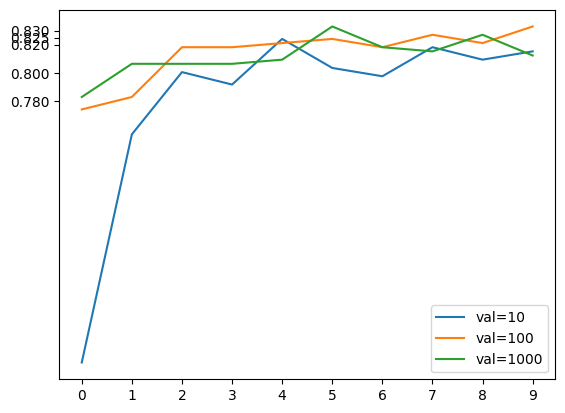

In [31]:
for size, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % size))

plt.xticks(np.arange(10))
plt.yticks([0.78, 0.80, 0.82, 0.825, 0.83])
plt.legend()

In [32]:
def make_model(learning_rate=0.01, size_inner=100, droprate=0.5):
    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(150, 150, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(150, 150, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    drop = keras.layers.Dropout(droprate)(inner)

    outputs = keras.layers.Dense(10)(drop)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [33]:
learning_rate = 0.001
size = 100

scores = {}

for droprate in [0.0, 0.2, 0.5, 0.8]:
    print(droprate)

    model = make_model(
        learning_rate=learning_rate,
        size_inner=size,
        droprate=droprate
    )

    history = model.fit(train_ds, epochs=30, validation_data=val_ds)
    scores[droprate] = history.history

    print()
    print()

0.0
Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 23s 172ms/step - accuracy: 0.6819 - loss: 0.9329 - val_accuracy: 0.7742 - val_loss: 0.6801
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.8276 - loss: 0.4962 - val_accuracy: 0.8065 - val_loss: 0.5863
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.8879 - loss: 0.3379 - val_accuracy: 0.7977 - val_loss: 0.5765
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - accuracy: 0.9208 - loss: 0.2504 - val_accuracy: 0.7977 - val_loss: 0.5788
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - accuracy: 0.9537 - loss: 0.1661 - val_accuracy: 0.8240 - val_loss: 0.5814
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 91ms/step - accuracy: 0.9762 - loss: 0.1138 - val_accuracy: 0.8094 - val_loss: 0.5820
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.9866 - loss: 0.0821 - val_accuracy: 0.8211 - val_loss: 0.6143
Epoch 8/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 98ms/step - accuracy: 0.9935 - loss: 0.0577 - val_accuracy: 0.83

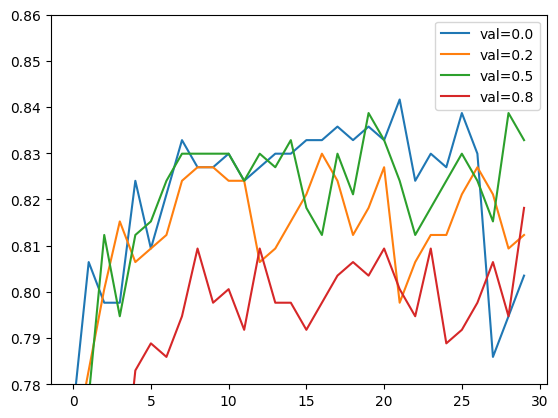

In [34]:
for droprate, hist in scores.items():
    plt.plot(hist['val_accuracy'], label=('val=%s' % droprate))

plt.ylim(0.78, 0.86)
plt.legend()

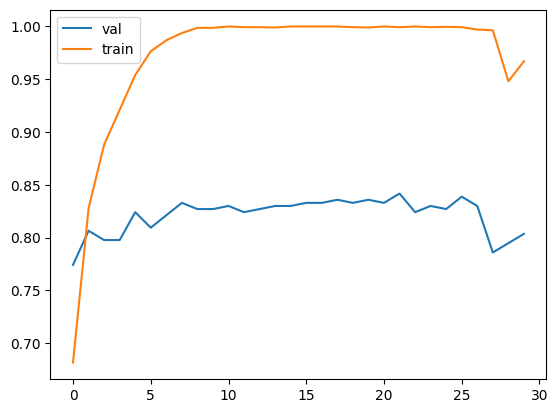

In [35]:
hist = scores[0.0]
plt.plot(hist['val_accuracy'], label='val')
plt.plot(hist['accuracy'], label='train')

plt.legend()

In [36]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=10,
    height_shift_range=10,
    shear_range=10,
    zoom_range=0.1,
    vertical_flip=True,
)

In [37]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
#     vertical_flip=True,
)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(150, 150),
    batch_size=32
)

val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(150, 150),
    batch_size=32,
    shuffle=False
)

Found 3068 images belonging to 10 classes.
Found 341 images belonging to 10 classes.


In [38]:
learning_rate = 0.001
size = 100
droprate = 0.2

model = make_model(
    learning_rate=learning_rate,
    size_inner=size,
    droprate=droprate
)

history = model.fit(train_ds, epochs=50, validation_data=val_ds)

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 24s 175ms/step - accuracy: 0.6457 - loss: 1.0515 - val_accuracy: 0.7713 - val_loss: 0.6675
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.7806 - loss: 0.6242 - val_accuracy: 0.8211 - val_loss: 0.5644
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.8341 - loss: 0.4660 - val_accuracy: 0.8035 - val_loss: 0.5958
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.8833 - loss: 0.3552 - val_accuracy: 0.8475 - val_loss: 0.5314
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 96ms/step - accuracy: 0.9087 - loss: 0.2768 - val_accuracy: 0.8211 - val_loss: 0.5640
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 100ms/step - accuracy: 0.9319 - loss: 0.2210 - val_accuracy: 0.8270 - val_loss: 0.5534
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 88ms/step - accuracy: 0.9478 - loss: 0.1734 - val_accuracy: 0.8065 - val_loss: 0.5978
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 97ms/step - accuracy: 0.9606 - loss: 0.1400 - val_accuracy: 0.83

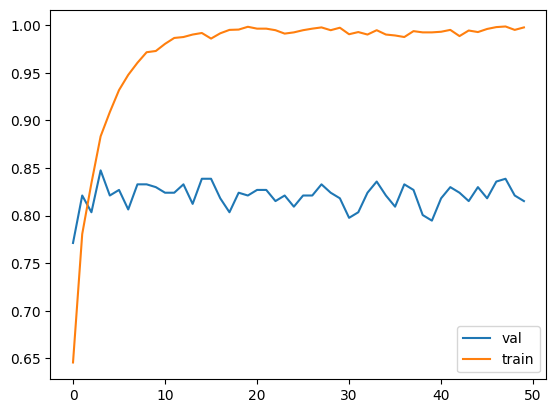

In [39]:
hist = history.history
plt.plot(hist['val_accuracy'], label='val')
plt.plot(hist['accuracy'], label='train')

plt.legend()

In [40]:
def make_model(input_size=150, learning_rate=0.01, size_inner=100,
               droprate=0.5):

    base_model = Xception(
        weights='imagenet',
        include_top=False,
        input_shape=(input_size, input_size, 3)
    )

    base_model.trainable = False

    #########################################

    inputs = keras.Input(shape=(input_size, input_size, 3))
    base = base_model(inputs, training=False)
    vectors = keras.layers.GlobalAveragePooling2D()(base)

    inner = keras.layers.Dense(size_inner, activation='relu')(vectors)
    drop = keras.layers.Dropout(droprate)(inner)

    outputs = keras.layers.Dense(10)(drop)

    model = keras.Model(inputs, outputs)

    #########################################

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    loss = keras.losses.CategoricalCrossentropy(from_logits=True)

    model.compile(
        optimizer=optimizer,
        loss=loss,
        metrics=['accuracy']
    )

    return model

In [41]:
input_size = 299

In [42]:
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    shear_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

train_ds = train_gen.flow_from_directory(
    './clothing-dataset-small/train',
    target_size=(input_size, input_size),
    batch_size=32
)


val_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_ds = val_gen.flow_from_directory(
    './clothing-dataset-small/validation',
    target_size=(input_size, input_size),
    batch_size=32,
    shuffle=False
)

Found 3068 images belonging to 10 classes.
Found 341 images belonging to 10 classes.


In [43]:
checkpoint = keras.callbacks.ModelCheckpoint(
    'xception_v4_1_{epoch:02d}_{val_accuracy:.3f}.h5',
    save_best_only=True,
    monitor='val_accuracy',
    mode='max'
)

In [ ]:
learning_rate = 0.0005
size = 100
droprate = 0.2

model = make_model(
    input_size=input_size,
    learning_rate=learning_rate,
    size_inner=size,
    droprate=droprate
)

history = model.fit(train_ds, epochs=50, validation_data=val_ds,
                   callbacks=[checkpoint])

In [45]:
import tensorflow as tf
from tensorflow import keras

In [47]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import load_img

from tensorflow.keras.applications.xception import preprocess_input

In [48]:
test_gen = ImageDataGenerator(preprocessing_function=preprocess_input)

test_ds = test_gen.flow_from_directory(
    './clothing-dataset-small/test',
    target_size=(299, 299),
    batch_size=32,
    shuffle=False
)

Found 372 images belonging to 10 classes.


In [49]:
model = keras.models.load_model('xception_v4_1_05_0.891.h5')

In [50]:
model.evaluate(test_ds)

12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.8978 - loss: 0.2887


[0.2887127101421356, 0.897849440574646]

In [51]:
path = 'clothing-dataset-small/test/pants/c8d21106-bbdb-4e8d-83e4-bf3d14e54c16.jpg'

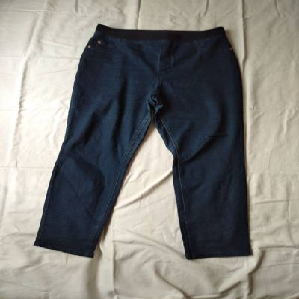

In [52]:
img = load_img(path, target_size=(299, 299))
img

In [53]:
import numpy as np

In [54]:
x = np.array(img)
X = np.array([x])
X.shape

(1, 299, 299, 3)

In [55]:
X = preprocess_input(X)
pred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [56]:
classes = [
    'dress',
    'hat',
    'longsleeve',
    'outwear',
    'pants',
    'shirt',
    'shoes',
    'shorts',
    'skirt',
    't-shirt'
]

In [60]:
dict(zip(classes, pred[0]))

{'dress': np.float32(-2.0415154),
 'hat': np.float32(-3.1595285),
 'longsleeve': np.float32(-0.2537482),
 'outwear': np.float32(-0.6453829),
 'pants': np.float32(8.591794),
 'shirt': np.float32(-1.1331949),
 'shoes': np.float32(-2.1789994),
 'shorts': np.float32(3.1126864),
 'skirt': np.float32(-2.202883),
 't-shirt': np.float32(-2.1083133)}